### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

### Data loading + appending with results from previous query

In [2]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [3]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (14, 2), y = (14,)
Function 2: X = (14, 2), y = (14,)
Function 3: X = (19, 3), y = (19,)
Function 4: X = (34, 4), y = (34,)
Function 5: X = (24, 4), y = (24,)
Function 6: X = (24, 5), y = (24,)
Function 7: X = (34, 6), y = (34,)
Function 8: X = (44, 8), y = (44,)


### Reusable functions

In [4]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [5]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [6]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [7]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [8]:
def plot_gp_2d(i, gp, suggestions=None):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean = gp.predict(X_grid)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    if suggestions:
        for name, point in suggestions.items():
            plt.scatter(*point, marker="X", s=120, label=name)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.legend()
    plt.show()

In [9]:
def plot_gp_uncertainty_2d(i, gp):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    _, std = gp.predict(X_grid, return_std=True)

    plt.contourf(x1, x2, std.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predictive uncertainty (std)")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP uncertainty")
    plt.show()

In [10]:
def plot_3d(i, suggestions=None):
    X, y = functions[i]["X"], functions[i]["y"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    p = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                   c=y, cmap="viridis", s=70)

    # Last week's query
    ax.scatter(*X[-1], marker="*", s=300,
               edgecolors="red", facecolors="none",
               linewidths=2, label="Last week's query")

    if suggestions:
        for name, point in suggestions.items():
            ax.scatter(*point, marker="X", s=150, label=name)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}")
    ax.legend()
    plt.colorbar(p, label="Output")
    plt.show()

In [11]:
def plot_3d_suggestions(i, suggestions):
    X = functions[i]["X"]
    y = functions[i]["y"]

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")

    # Existing observations
    p = ax.scatter(X[:,0], X[:,1], X[:,2], c=y, cmap="viridis", s=60)
    plt.colorbar(p, label="Output")

    # Acquisition suggestions
    markers = {"UCB": "^", "EI": "s", "PI": "X"}

    for name, point in suggestions.items():
        ax.scatter(
            point[0], point[1], point[2],
            marker=markers[name],
            s=180,
            label=name
        )

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}: Acquisition Suggestions")
    ax.legend()

    plt.show()

In [12]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

In [13]:
def check_uncertainty(gp, suggestions):
    for name, point in suggestions.items():
        mean, std = gp.predict(point.reshape(1, -1), return_std=True)

        print(
            f"{name}: mean={mean[0]:.4f}, "
            f"uncertainty={std[0]:.4f}"
        )

In [14]:
def plot_scores(i):
    y = functions[i]["y"]
    positions = np.arange(len(y))
    best = np.argmax(y)

    plt.figure(figsize=(10, 5))
    plt.scatter(positions, y, s=70)

    # Label points with array position
    for pos, score in zip(positions, y):
        plt.annotate(str(pos), (pos, score),
                     xytext=(5, 5),
                     textcoords="offset points")

    # Last week's query
    plt.scatter(positions[-1], y[-1],
                marker="*", s=250,
                facecolors="none", edgecolors="red",
                linewidths=2, label="Last week's query")

    # Best observation
    plt.scatter(best, y[best],
                marker="X", s=200,
                label="Best score")

    plt.xlabel("Array position")
    plt.ylabel("Observed score")
    plt.title(f"Function {i}: Observed Scores")
    plt.legend()
    plt.show()

In [15]:
def uncertainty_search(gp, candidates, ranges):
    mean, std = gp.predict(candidates, return_std=True)

    for low, high in ranges:
        mask = (std >= low) & (std < high)

        if mask.any():
            idx = np.argmax(mean[mask])
            point = candidates[mask][idx]

            print(
                f"std {low:.2f}-{high:.2f}:",
                np.round(point, 3),
                f"mean={mean[mask][idx]:.3f}",
                f"std={std[mask][idx]:.3f}"
            )

In [43]:
def plot_input_sensitivity(gp, best_x, n_points=100):
    values = np.linspace(0, 1, n_points)

    for j in range(len(best_x)):
        X_test = np.tile(best_x, (n_points, 1))
        X_test[:, j] = values

        mean, std = gp.predict(X_test, return_std=True)

        plt.figure(figsize=(7, 4))
        plt.plot(values, mean)
        plt.fill_between(
            values,
            mean - std,
            mean + std,
            alpha=0.2
        )

        plt.axvline(best_x[j], linestyle="--")
        plt.xlabel(f"x{j + 1}")
        plt.ylabel("GP predicted output")
        plt.title(f"F4 sensitivity to x{j + 1}")
        plt.show()

In [16]:
def format_query(point):
    return "-".join(f"{v:.6f}" for v in point)

### Neural networks

This week's content introduces neural networks, so I want to explore whether they can provide any useful additional insights for my bbo strategy, particularly when modelling non-linear relationships and identifying influential input variables.

In [17]:
import tensorflow as tf

In [18]:
def build_nn(input_dim):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

In [19]:
def train_nn(i, labels, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    y = labels.astype(np.float32).reshape(-1, 1)

    input_size = X.shape[1]

    W1 = tf.Variable(
        tf.random.normal([input_size, hidden_size], stddev=0.1, seed=42)
    )
    b1 = tf.Variable(tf.zeros([hidden_size]))

    W2 = tf.Variable(
        tf.random.normal([hidden_size, 1], stddev=0.1, seed=42)
    )
    b2 = tf.Variable(tf.zeros([1]))

    def forward_pass(x):
        hidden = tf.nn.relu(tf.matmul(x, W1) + b1)
        logits = tf.matmul(hidden, W2) + b2
        output = tf.nn.sigmoid(logits)
        return output

    loss_fn = tf.keras.losses.BinaryCrossentropy()
    optimizer = tf.optimizers.SGD(learning_rate=lr)

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            y_pred = forward_pass(X)
            loss = loss_fn(y, y_pred)

        gradients = tape.gradient(
            loss, [W1, b1, W2, b2]
        )

        optimizer.apply_gradients(
            zip(gradients, [W1, b1, W2, b2])
        )

    return forward_pass, loss.numpy()

In [20]:
# Creates good/bad labels for NN classification
# Can use either a percentile or a manually chosen threshold

def create_labels(i, percentile=None, threshold=None):
    y = functions[i]["y"]

    if threshold is None:
        if percentile is None:
            percentile = 60
        threshold = np.percentile(y, percentile)

    labels = (y >= threshold).astype(np.float32)

    print(f"Function {i}")
    print(f"Threshold: {threshold}")
    print(f"Good observations: {int(np.sum(labels))}")
    print(f"Bad observations: {int(np.sum(labels == 0))}")

    return labels, threshold

In [21]:
def nn_loocv(i, labels, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    labels = labels.astype(np.float32)

    predictions = []
    actual = []

    for test_idx in range(len(X)):
        # Leave one observation out
        train_mask = np.arange(len(X)) != test_idx

        X_train = X[train_mask]
        y_train = labels[train_mask].reshape(-1, 1)

        X_test = X[test_idx:test_idx + 1]
        y_test = int(labels[test_idx])

        # Build a new NN for this fold
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(X.shape[1],)),
            tf.keras.layers.Dense(hidden_size, activation="relu"),
            tf.keras.layers.Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=tf.keras.optimizers.SGD(learning_rate=lr),
            loss="binary_crossentropy"
        )

        model.fit(
            X_train,
            y_train,
            epochs=epochs,
            verbose=0
        )

        # Probability of GOOD
        probability = model.predict(X_test, verbose=0)[0, 0]

        # >= 0.5 = GOOD
        predicted_class = int(probability >= 0.5)

        predictions.append(predicted_class)
        actual.append(y_test)

        print(
            f"Point {test_idx + 1}: "
            f"P(good)={probability:.3f}, "
            f"predicted={predicted_class}, "
            f"actual={y_test}"
        )

    predictions = np.array(predictions)
    actual = np.array(actual)

    accuracy = np.mean(predictions == actual)

    print(f"\nLOOCV accuracy: {accuracy:.3f}")

    return accuracy

In [22]:
def input_gradient(i, model):
    X = functions[i]["X"].astype(np.float32)
    y = functions[i]["y"]

    # Current best observed input
    best_x = X[np.argmax(y)]

    # Make input a TensorFlow variable so we can differentiate w.r.t. it
    x = tf.Variable(best_x.reshape(1, -1))

    with tf.GradientTape() as tape:
        prediction = model(x)

    gradient = tape.gradient(prediction, x).numpy()[0]

    print("Best point:", best_x)
    print("NN prediction:", prediction.numpy()[0, 0])
    print("Input gradients:", gradient)
    print(
        "Most influential input:",
        f"x{np.argmax(np.abs(gradient)) + 1}"
    )

    return gradient

In [58]:
def train_regression_nn(i, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    y = functions[i]["y"].astype(np.float32).reshape(-1, 1)

    input_size = X.shape[1]

    W1 = tf.Variable(
        tf.random.normal([input_size, hidden_size], stddev=0.1, seed=42)
    )
    b1 = tf.Variable(tf.zeros([hidden_size]))

    W2 = tf.Variable(
        tf.random.normal([hidden_size, 1], stddev=0.1, seed=42)
    )
    b2 = tf.Variable(tf.zeros([1]))

    def forward_pass(x):
        hidden = tf.nn.relu(tf.matmul(x, W1) + b1)
        output = tf.matmul(hidden, W2) + b2
        return output

    loss_fn = tf.keras.losses.MeanSquaredError()
    optimizer = tf.optimizers.SGD(learning_rate=lr)

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            y_pred = forward_pass(X)
            loss = loss_fn(y, y_pred)

        gradients = tape.gradient(loss, [W1, b1, W2, b2])

        optimizer.apply_gradients(
            zip(gradients, [W1, b1, W2, b2])
        )

    return forward_pass, loss.numpy()

In [60]:
def nn_regression_loocv(i, hidden_size=8, epochs=1000, lr=0.01):
    X = functions[i]["X"].astype(np.float32)
    y = functions[i]["y"].astype(np.float32)

    errors = []

    for test_idx in range(len(X)):
        X_train = np.delete(X, test_idx, axis=0)
        y_train = np.delete(y, test_idx).reshape(-1, 1)

        X_test = X[test_idx:test_idx + 1]
        y_test = y[test_idx]

        input_size = X.shape[1]

        W1 = tf.Variable(
            tf.random.normal(
                [input_size, hidden_size],
                stddev=0.1,
                seed=42
            )
        )
        b1 = tf.Variable(tf.zeros([hidden_size]))

        W2 = tf.Variable(
            tf.random.normal(
                [hidden_size, 1],
                stddev=0.1,
                seed=42
            )
        )
        b2 = tf.Variable(tf.zeros([1]))

        def forward_pass(x):
            hidden = tf.nn.relu(tf.matmul(x, W1) + b1)
            return tf.matmul(hidden, W2) + b2

        loss_fn = tf.keras.losses.MeanSquaredError()
        optimizer = tf.optimizers.SGD(learning_rate=lr)

        for epoch in range(epochs):
            with tf.GradientTape() as tape:
                prediction = forward_pass(X_train)
                loss = loss_fn(y_train, prediction)

            gradients = tape.gradient(
                loss,
                [W1, b1, W2, b2]
            )

            optimizer.apply_gradients(
                zip(gradients, [W1, b1, W2, b2])
            )

        prediction = forward_pass(X_test).numpy()[0, 0]
        error = abs(prediction - y_test)
        errors.append(error)

        print(
            f"Point {test_idx + 1}: "
            f"predicted={prediction:.4f}, "
            f"actual={y_test:.4f}, "
            f"error={error:.4f}"
        )

    mae = np.mean(errors)

    print(f"\nLOOCV MAE: {mae:.6f}")

    return mae

### Function 1

In [23]:
check_result(1)

Function 1
Latest: X=[0.804414 0.7151  ], y=-2.766222565976174e-27
Best:   X=[0.73102363 0.73299988], y=7.710875114502849e-16


#### checking observation distribution

In [24]:
y = functions[1]["y"]

for value in np.sort(y):
    print(f"{value:.3e}")

-3.606e-03
-1.618e-05
-4.549e-20
-2.766e-27
-5.885e-49
-2.159e-54
-2.089e-91
3.342e-124
3.607e-81
1.323e-79
6.230e-48
1.033e-46
2.535e-40
7.711e-16


#### Visualising the data

using transformations to make sense of the data

In [25]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.69230769 0.84615385 1.         0.53846036 0.         0.38461538
 0.46153846 0.92307692 0.61538462 0.76923077 0.30769231 0.15384615
 0.07692308 0.23076923]


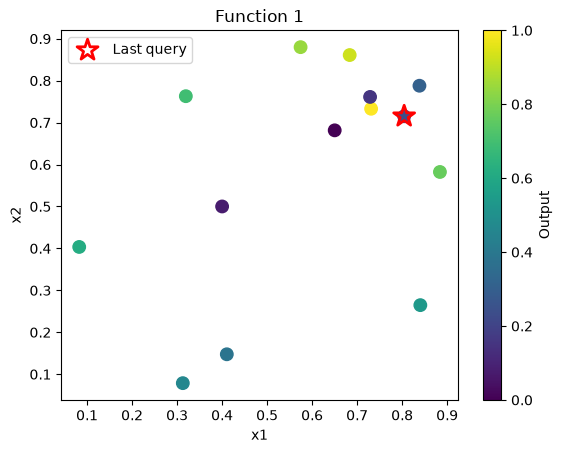

In [26]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

#### chosen query for F1

`0.750000-0.870000`

Given how scattered the observations and results are, I think the most effective way to optimise F1 is through manual exploration of the search space. I considered training a neural network as a classifier to distinguish between good and bad regions, but with only two observations classified as ‘bad’ and the rest as ‘good’, the class imbalance would make the model unreliable. My GP hasn’t been particularly helpful either, so I think the most sensible strategy is to prioritise exploration with each query, then shift towards exploitation as we approach the end of the BBO process.

### Function 2

Function 2
Latest: X=[0.702637 1.      ], y=0.6710529877291967
Best:   X=[0.702637 1.      ], y=0.6710529877291967


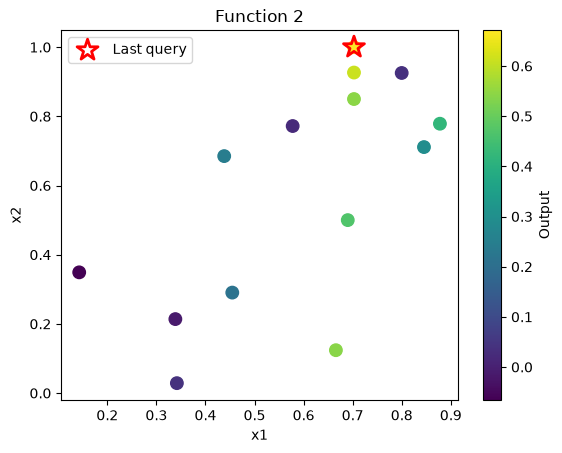

In [27]:
check_result(2)
plot_2d(2)

In [28]:
validate_kernels(2)

[(('Matern', 0.1), np.float64(0.20915102320736106)),
 (('RQ', 0.05), np.float64(0.2092986807518393)),
 (('RQ', 0.1), np.float64(0.21192592141213668)),
 (('RBF', 0.1), np.float64(0.2140265509289398)),
 (('RBF', 0.05), np.float64(0.21439981380328196)),
 (('Matern', 0.05), np.float64(0.21861925994942602)),
 (('Matern', 0.2), np.float64(0.24717561472354926)),
 (('RQ', 0.2), np.float64(0.26453519247758717)),
 (('Matern', 0.5), np.float64(0.3590492919866177)),
 (('RBF', 0.2), np.float64(0.45760138545172874)),
 (('RQ', 0.5), np.float64(0.7661052054664185)),
 (('RBF', 0.5), np.float64(1.849646848120559))]

In [29]:
best_kernel_f2 = Matern(length_scale=0.1)

gp_f2 = fit_gp(2, best_kernel_f2)

In [30]:
np.random.seed(42)
X_candidates = np.random.uniform(0, 1, (50000, 2))

best_y = functions[2]["y"].max()

In [31]:
suggestions = {}

for beta in [1.96, 3, 4]:
    result = acquisitions(
        gp_f2,
        X_candidates,
        best_y,
        beta=beta
    )

    suggestions[f"UCB β={beta}"] = result["UCB"]

    print(f"Beta {beta}: {result['UCB']}")

Beta 1.96: [0.63121781 0.98233327]
Beta 3: [0.60959157 0.99190149]
Beta 4: [0.59004819 0.9981298 ]


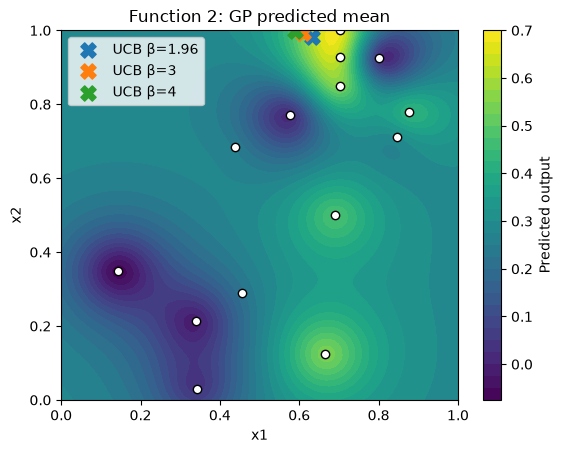

In [32]:
plot_gp_2d(2, gp_f2, suggestions)

Again the GP suggestions cluster around the best performing point, so I want to manually explore around another promising area around 0.67, 0.1.

#### chosen query for F2

`0.70263656, 0.10000000`

### Function 3

In [33]:
check_result(3)

Function 3
Latest: X=[0.213995 0.283284 0.400313], y=-0.03564707174254631
Best:   X=[0.181135 0.270895 0.418968], y=-0.027149095597068146


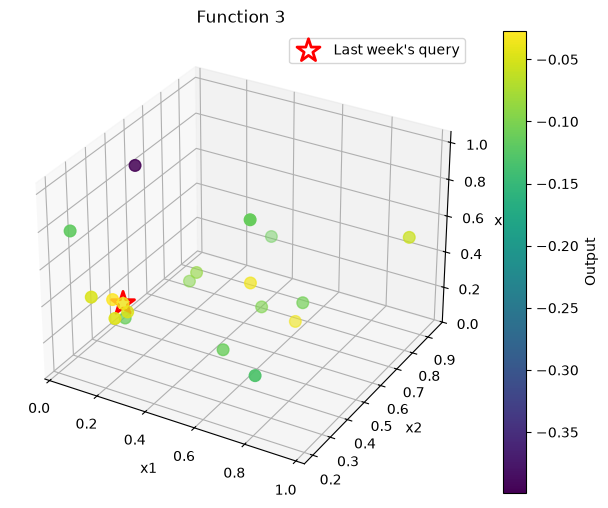

In [34]:
plot_3d(3)

#### checking points spread to support threshold for NN classifier

In [35]:
y = functions[3]["y"]

for value in np.sort(y):
    print(f"{value:.6f}")

-0.398926
-0.131461
-0.118048
-0.113869
-0.112122
-0.111415
-0.110621
-0.105965
-0.099521
-0.094190
-0.087963
-0.056758
-0.048008
-0.046947
-0.045230
-0.036378
-0.035647
-0.034835
-0.027149


In [36]:
labels_f3, threshold_f3 = create_labels(3, threshold=-0.06)

Function 3
Threshold: -0.06
Good observations: 8
Bad observations: 11


In [37]:
nn_f3, loss_f3 = train_nn(3, labels_f3)

print("Classification training loss:", loss_f3)

Classification training loss: 0.679407


In [38]:
accuracy_f3 = nn_loocv(3, labels_f3)

Point 1: P(good)=0.460, predicted=0, actual=0
Point 2: P(good)=0.467, predicted=0, actual=0
Point 3: P(good)=0.460, predicted=0, actual=0
Point 4: P(good)=0.384, predicted=0, actual=1
Point 5: P(good)=0.430, predicted=0, actual=1
Point 6: P(good)=0.375, predicted=0, actual=0
Point 7: P(good)=0.459, predicted=0, actual=0
Point 8: P(good)=0.434, predicted=0, actual=0
Point 9: P(good)=0.470, predicted=0, actual=0
Point 10: P(good)=0.441, predicted=0, actual=0
Point 11: P(good)=0.432, predicted=0, actual=1
Point 12: P(good)=0.458, predicted=0, actual=0
Point 13: P(good)=0.481, predicted=0, actual=0
Point 14: P(good)=0.223, predicted=0, actual=1
Point 15: P(good)=0.302, predicted=0, actual=1
Point 16: P(good)=0.446, predicted=0, actual=0
Point 17: P(good)=0.398, predicted=0, actual=1
Point 18: P(good)=0.437, predicted=0, actual=1
Point 19: P(good)=0.425, predicted=0, actual=1

LOOCV accuracy: 0.579


#### mini reflection on using an NN classifier

this function gave a fairly balanced split of 8 good and 11 bad observations, so i thought a NN classifier might work well here. however, LOOCV accuracy was only 52.6%, which is worse than the 57.9% accuracy achieved by simply predicting the majority ‘bad’ class every time. 

the NN predicted 18/19 observations as bad, meaning it had not learned a useful decision boundary. so, I will not use the classifier to select my next query - there is just too little data.

#### back to GP strategy

In [39]:
validate_kernels(3)

[(('Matern', 0.1), np.float64(0.038748991503168725)),
 (('RQ', 0.05), np.float64(0.03903921222478226)),
 (('RQ', 0.1), np.float64(0.03954298795477479)),
 (('RBF', 0.1), np.float64(0.04001679272728438)),
 (('RBF', 0.05), np.float64(0.0402802573320854)),
 (('Matern', 0.05), np.float64(0.04070968524768263)),
 (('Matern', 0.2), np.float64(0.045677082124098066)),
 (('RQ', 0.2), np.float64(0.05172292381311383)),
 (('RBF', 0.2), np.float64(0.0573724082736847)),
 (('Matern', 0.5), np.float64(0.07761101524021623)),
 (('RQ', 0.5), np.float64(0.11365715334018318)),
 (('RBF', 0.5), np.float64(0.17127942717963016))]

In [46]:
best_kernel_f3 = Matern(length_scale=0.1)
gp_f3 = fit_gp(3, best_kernel_f3)

In [47]:
X_candidates = np.random.uniform(0, 1, (50000, 3))

best_y_f3 = np.max(functions[3]["y"])

suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates,
    best_y_f3
)

suggestions_f3

{'UCB': array([0.42550004, 0.52754512, 0.42206343]),
 'EI': array([0.1541448 , 0.21690339, 0.37314233]),
 'PI': array([0.18575348, 0.26122718, 0.39254171])}

In [48]:
check_uncertainty(gp_f3, suggestions_f3)

UCB: mean=-0.0746, uncertainty=0.0749
EI: mean=-0.0467, uncertainty=0.0554
PI: mean=-0.0297, uncertainty=0.0272


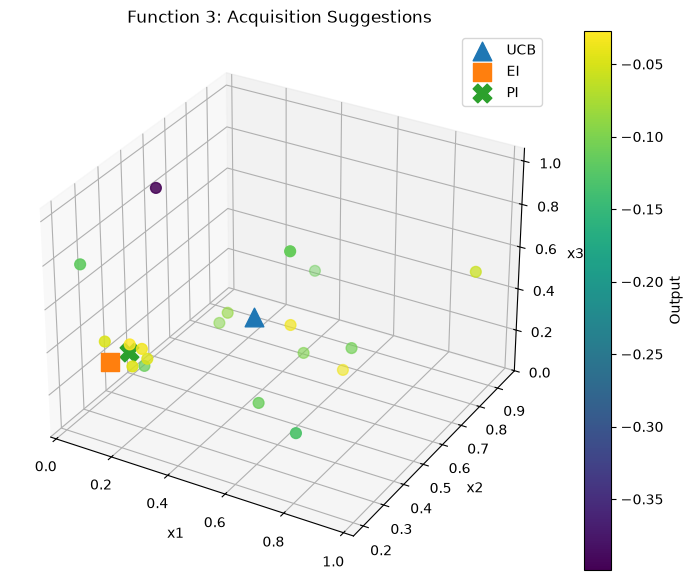

In [49]:
plot_3d_suggestions(3, suggestions_f3)

In [50]:
print(format_query(suggestions_f3["UCB"]))

0.425500-0.527545-0.422063


#### chosen query for F3

`0.425500-0.527545-0.422063`

The GP's PI and EI suggestions remained relatively close to the current best, whereas UCB suggested a much less explored point with high uncertainty. Since my best result came from exploration in Round 2 and local exploitation has not improved it in the last two rounds, I chose UCB to explore a different region this round.

### Function 4

After rereading the function description, I realised there is a risk of becoming trapped in a local optimum, so I need to be more careful about how I tune each hyperparameter. 

Since changing all four inputs at once makes it difficult to tell which changes are actually improving the score, I will use the GP as a cheap surrogate to analyse the effect of each input individually around my current best point. So I'm essentially using the GP for a sensitivity analysis, but not treat its predictions as very reliable. 

This should help me make more informed query decisions rather than continuing to tune all four parameters simultaneously.

In [40]:
validate_kernels(4)

[(('RQ', 0.5), np.float64(1.7451167904118208)),
 (('Matern', 0.5), np.float64(2.110105984091941)),
 (('RBF', 0.5), np.float64(2.4551440684383294)),
 (('RQ', 0.2), np.float64(2.7382639115494007)),
 (('RBF', 0.2), np.float64(3.1520878160942316)),
 (('Matern', 0.2), np.float64(3.2119044673349197)),
 (('RQ', 0.1), np.float64(3.60562155414294)),
 (('RBF', 0.1), np.float64(4.339020984553746)),
 (('Matern', 0.1), np.float64(4.416886158179011)),
 (('RQ', 0.05), np.float64(4.676033508303677)),
 (('Matern', 0.05), np.float64(5.559149861572594)),
 (('RBF', 0.05), np.float64(5.561274013004883))]

In [41]:
best_kernel_f4 = RationalQuadratic(length_scale=0.5)
gp_f4 = fit_gp(4, best_kernel_f4)

In [42]:
best_x_f4 = np.array([0.47, 0.43, 0.42, 0.38])

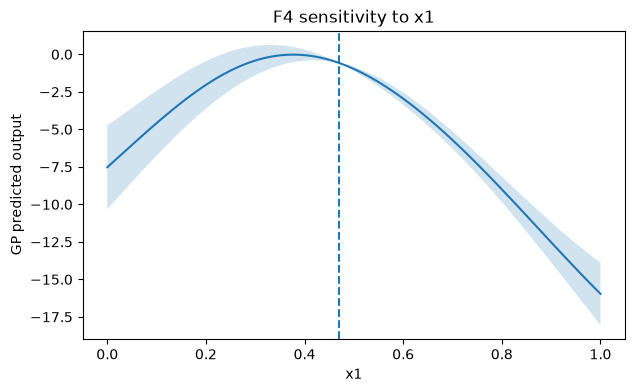

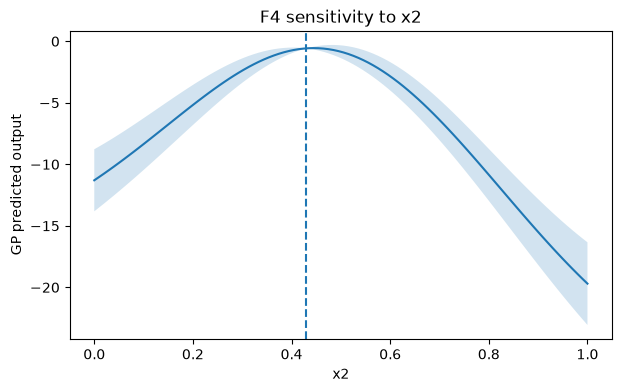

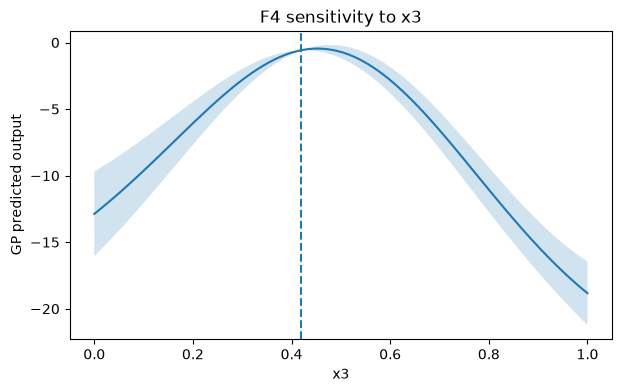

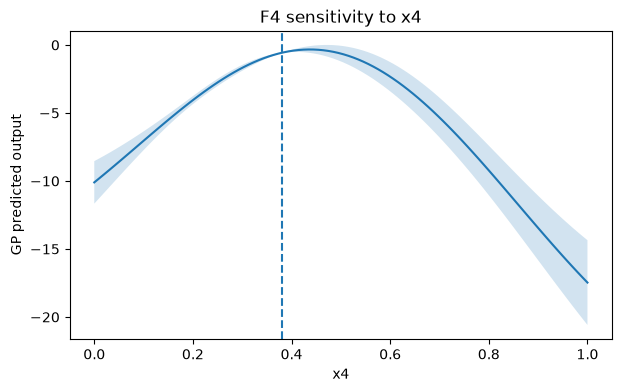

In [44]:
plot_input_sensitivity(gp_f4, best_x_f4)

These plots suggest the directions to tune each hyperparameter to achieve the local peak. For example; for x1, but the predicted peak looks closer to roughly 0.37–0.40 compared to the current value of 0.47. So the GP is suggesting that decreasing x1 slightly could improve the score.

Since the GP has a relatively high LOOCV error, I'll focus only on the more substantial suggestions of adjustments when tuning - i.e. only x1 and x4 - since the predicted peaks may not be entirely reliable.

#### constructing a round 5 candidate

In [47]:
# candidates where we decrease x1 and increase x4

candidates_f4 = np.array([
    [0.45, 0.43, 0.42, 0.40],
    [0.43, 0.43, 0.42, 0.42],
    [0.41, 0.43, 0.42, 0.44],
    [0.43, 0.44, 0.43, 0.42],
    [0.41, 0.44, 0.43, 0.44]
])

mean, std = gp_f4.predict(candidates_f4, return_std=True)

for point, m, s in zip(candidates_f4, mean, std):
    print(
        f"{point} -> "
        f"mean={m:.4f}, uncertainty={s:.4f}"
    )

[0.45 0.43 0.42 0.4 ] -> mean=-0.2156, uncertainty=0.1043
[0.43 0.43 0.42 0.42] -> mean=0.0525, uncertainty=0.2308
[0.41 0.43 0.42 0.44] -> mean=0.2171, uncertainty=0.3760
[0.43 0.44 0.43 0.42] -> mean=0.1369, uncertainty=0.2537
[0.41 0.44 0.43 0.44] -> mean=0.3008, uncertainty=0.3868


The predicted output improves consistently as I move in these directions (decreasing x1, increasing x4 and slightly adjusting x2 and x3)

However, uncertainty also increases as the changes became larger. 

I therefore want to choose [0.43, 0.44, 0.43, 0.42] as a controlled adjustment from the current best rather than moving directly towards the GP's predicted optimum. 

This allows me to continue tuning the hyperparameters while reducing the risk of relying too heavily on an uncertain surrogate model.

In [48]:
print(format_query([0.43, 0.44, 0.43, 0.42]))

0.430000-0.440000-0.430000-0.420000


#### chosen query for F4

`0.430000-0.440000-0.430000-0.420000`

### Function 5

made another huge improvement so will continue working on refinement

In [49]:
check_result(5)
validate_kernels(5)

Function 5
Latest: X=[0.154973 1.       0.99863  0.909479], y=3396.666636750134
Best:   X=[0.154973 1.       0.99863  0.909479], y=3396.666636750134


[(('RQ', 0.5), np.float64(69.54140836413627)),
 (('Matern', 0.5), np.float64(77.22093580519469)),
 (('RQ', 0.2), np.float64(108.9281002115376)),
 (('RBF', 0.5), np.float64(143.41052650070932)),
 (('Matern', 0.2), np.float64(207.99734832370322)),
 (('RBF', 0.2), np.float64(216.1567699487538)),
 (('RQ', 0.1), np.float64(234.49538418207408)),
 (('RQ', 0.05), np.float64(371.63042148526984)),
 (('RBF', 0.1), np.float64(373.47693108305725)),
 (('Matern', 0.1), np.float64(378.50913965712056)),
 (('RBF', 0.05), np.float64(463.4747582049951)),
 (('Matern', 0.05), np.float64(483.32511671339694))]

In [50]:
best_kernel_f5 = RationalQuadratic(length_scale=0.5)
gp_f5 = fit_gp(5, best_kernel_f5)

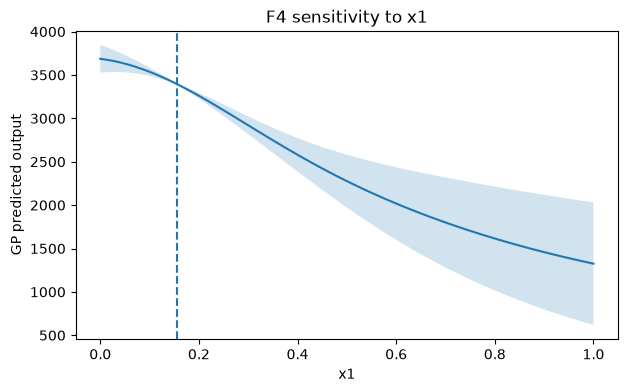

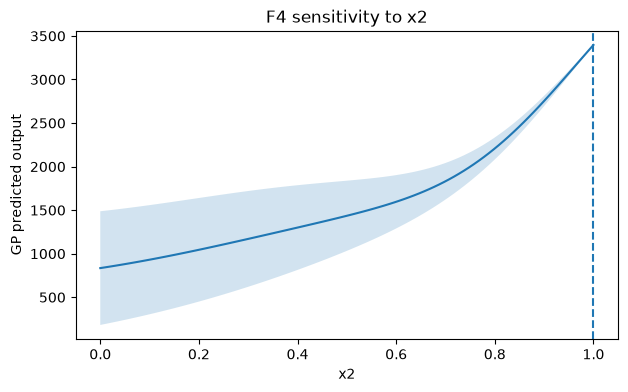

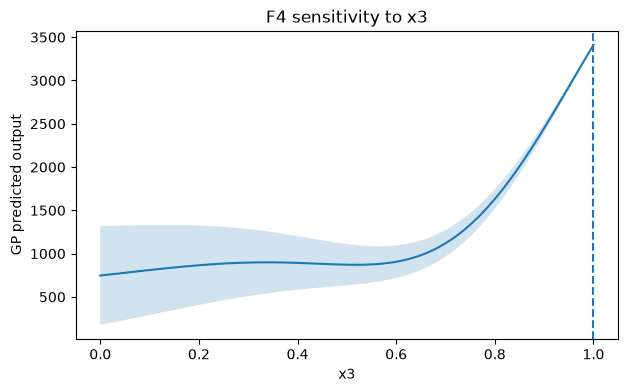

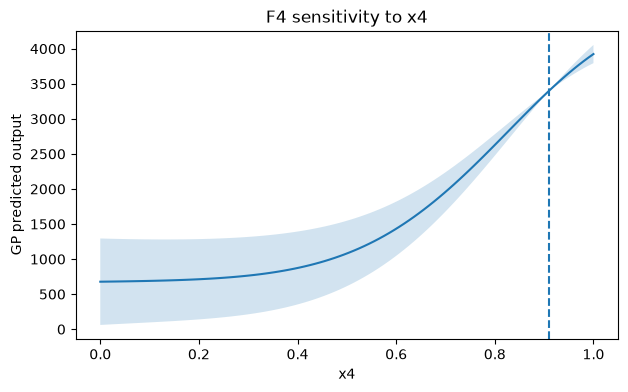

In [52]:
best_x_f5 = np.array([0.154973, 1.0, 0.998630, 0.909479])

plot_input_sensitivity(
    gp_f5,
    best_x_f5
)

Looks like I should decrease x1 and increase x4 while keeping x2 and x3 fixed.

In [53]:
candidates_f5 = np.array([
    [0.14, 1.0, 0.99863, 0.92],
    [0.12, 1.0, 0.99863, 0.94],
    [0.10, 1.0, 0.99863, 0.96],
    [0.08, 1.0, 0.99863, 0.98],
    [0.06, 1.0, 0.99863, 1.00]
])

mean, std = gp_f5.predict(candidates_f5, return_std=True)

for point, m, s in zip(candidates_f5, mean, std):
    print(
        f"{point} -> "
        f"mean={m:.2f}, uncertainty={s:.2f}"
    )

[0.14    1.      0.99863 0.92   ] -> mean=3506.55, uncertainty=17.88
[0.12    1.      0.99863 0.94   ] -> mean=3681.16, uncertainty=49.55
[0.1     1.      0.99863 0.96   ] -> mean=3839.58, uncertainty=82.70
[0.08    1.      0.99863 0.98   ] -> mean=3979.26, uncertainty=117.17
[0.06    1.      0.99863 1.     ] -> mean=4098.26, uncertainty=152.76


The GP sensitivity analysis supported the trend seen across previous rounds: decreasing x1 and increasing x4 appears to improve the output, while x2 and x3 are already at their upper boundaries. Testing increasingly large adjustments showed a consistent increase in predicted output, but also increasing uncertainty. I therefore selected [0.10, 1.00, 0.99863, 0.96] as a moderate local refinement, continuing to exploit the successful region without moving directly to the boundaries.

In [54]:
print(format_query([0.1,1.,0.99863,0.96]))

0.100000-1.000000-0.998630-0.960000


#### chosen query for F5

`0.100000-1.000000-0.998630-0.960000`

### Function 6

In [55]:
check_result(6)
validate_kernels(6)

Function 6
Latest: X=[0.36399  0.291166 0.565691 0.852364 0.24097 ], y=-0.425461991236611
Best:   X=[0.45433  0.363869 0.508315 0.757164 0.150167], y=-0.2049823948689158


[(('RQ', 0.5), np.float64(0.18105932377576064)),
 (('RBF', 0.5), np.float64(0.21101175319483456)),
 (('Matern', 0.5), np.float64(0.21418377919983375)),
 (('RQ', 0.2), np.float64(0.24859372478807581)),
 (('RBF', 0.2), np.float64(0.30868581918092924)),
 (('Matern', 0.2), np.float64(0.30940714379291806)),
 (('RQ', 0.1), np.float64(0.3399587053121202)),
 (('RBF', 0.1), np.float64(0.40706819161041397)),
 (('Matern', 0.1), np.float64(0.4126342618914601)),
 (('RQ', 0.05), np.float64(0.4172770714468512)),
 (('Matern', 0.05), np.float64(0.4669718525194271)),
 (('RBF', 0.05), np.float64(0.47019962328924464))]

In [56]:
best_kernel_f6 = RationalQuadratic(length_scale=0.5)
gp_f6 = fit_gp(6, best_kernel_f6)

In [59]:
# testing NN strategy

nn_f6, loss_f6 = train_regression_nn(6)
print("Training loss:", loss_f6)

Training loss: 0.091810964


In [61]:
nn_f6_mae = nn_regression_loocv(6)

Point 1: predicted=-0.8534, actual=-0.7143, error=0.1391
Point 2: predicted=-1.5086, actual=-1.2100, error=0.2987
Point 3: predicted=-2.0339, actual=-1.6722, error=0.3617
Point 4: predicted=-1.0869, actual=-1.5361, error=0.4491
Point 5: predicted=-1.2170, actual=-0.8292, error=0.3877
Point 6: predicted=-1.0709, actual=-1.2470, error=0.1761
Point 7: predicted=-0.9373, actual=-1.2338, error=0.2965
Point 8: predicted=-0.8770, actual=-1.6943, error=0.8173
Point 9: predicted=-1.7929, actual=-2.5712, error=0.7783
Point 10: predicted=-1.3809, actual=-1.3091, error=0.0718
Point 11: predicted=-1.4973, actual=-1.1448, error=0.3525
Point 12: predicted=-1.2322, actual=-1.9127, error=0.6805
Point 13: predicted=-1.5236, actual=-1.6228, error=0.0993
Point 14: predicted=-1.0943, actual=-1.3567, error=0.2623
Point 15: predicted=-2.1551, actual=-2.0184, error=0.1367
Point 16: predicted=-1.7921, actual=-1.7026, error=0.0896
Point 17: predicted=-1.6072, actual=-1.2942, error=0.3130
Point 18: predicted=-1.

The NN's error is about 80% higher than the GP's. It particularly struggles with the high-performing recipes close to zero. That's exactly the region we need it to understand for optimisation. So I won't be using it to choose this query.

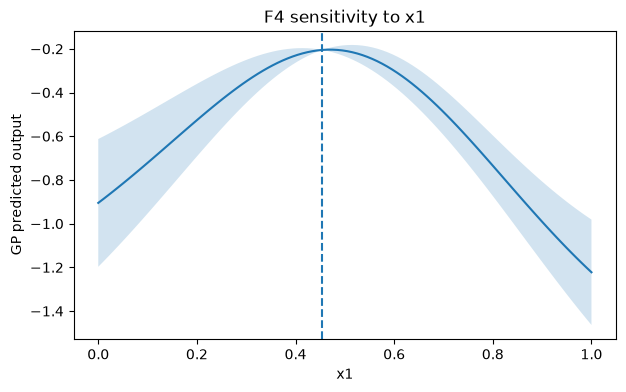

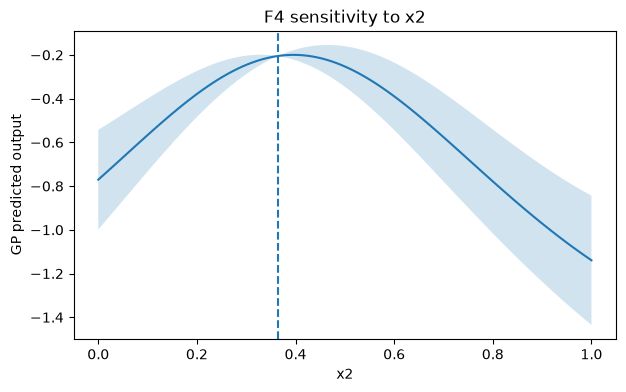

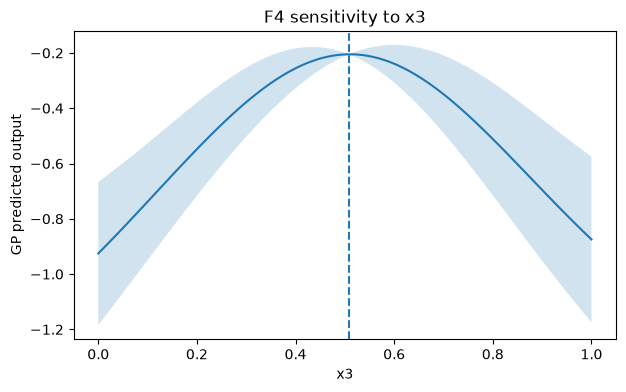

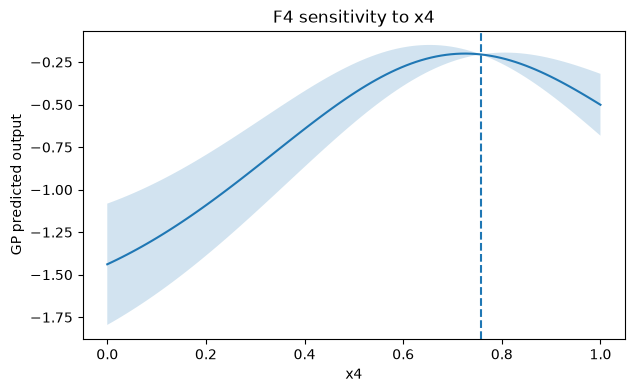

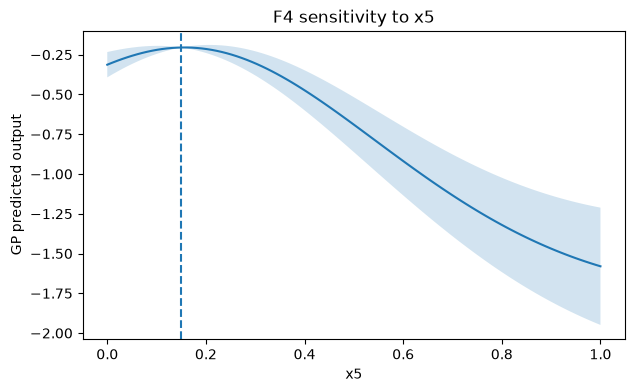

In [65]:
best_x_f6 = np.array([
    0.454330,
    0.363869,
    0.508315,
    0.757164,
    0.150167
])

plot_input_sensitivity(gp_f6, best_x_f6)

The GP sensitivity analysis suggests that the current best recipe is already close to a local optimum across all five inputs, so I need to tighten my search around the best.

The function description does not indicate the presence of multiple local optima, unlike some of the other functions. Combined with the sensitivity analysis, which places the current best recipe close to the predicted optimum for each input, I will focus on small local adjustments rather than broader exploration.

#### exploiting around the promising region - tightening the search

In [66]:
best = functions[6]["X"][np.argmax(functions[6]["y"])]

rng = np.random.RandomState(42)

X_candidates_f6 = best + rng.uniform(
    -0.05, 0.05,
    (20000, 5)
)

X_candidates_f6 = np.clip(X_candidates_f6, 0, 1)

suggestions_f6 = acquisitions(
    gp_f6,
    X_candidates_f6,
    best_y=functions[6]["y"].max()
)

suggestions_f6

{'UCB': array([0.40530105, 0.41183677, 0.46128259, 0.70830076, 0.18592301]),
 'EI': array([0.46243212, 0.4071264 , 0.55044422, 0.71096367, 0.14153385]),
 'PI': array([0.47223383, 0.37564791, 0.50920375, 0.74412586, 0.15148976])}

In [67]:
check_uncertainty(gp_f6, suggestions_f6)

UCB: mean=-0.2296, uncertainty=0.0790
EI: mean=-0.2042, uncertainty=0.0580
PI: mean=-0.1974, uncertainty=0.0119


In [68]:
print(format_query(suggestions_f6["PI"]))

0.472234-0.375648-0.509204-0.744126-0.151490


#### chosen query for F6

`0.472234-0.375648-0.509204-0.744126-0.151490`

chosen because the sensitivity analysis predicts we are already close to the best, so hoping PI will improve the score.

### Function 7

In [69]:
check_result(7)
validate_kernels(7)

Function 7
Latest: X=[0.174163 0.270107 0.182087 0.25951  0.282083 0.718177], y=2.607862873045956
Best:   X=[0.174163 0.270107 0.182087 0.25951  0.282083 0.718177], y=2.607862873045956


[(('RQ', 0.5), np.float64(0.2194137534280415)),
 (('Matern', 0.5), np.float64(0.22241206394432386)),
 (('RQ', 0.2), np.float64(0.23543353167239822)),
 (('Matern', 0.2), np.float64(0.27701607653258536)),
 (('RBF', 0.2), np.float64(0.27916693201774384)),
 (('RBF', 0.5), np.float64(0.2896489143298837)),
 (('RQ', 0.1), np.float64(0.2918979503423437)),
 (('Matern', 0.1), np.float64(0.3499194453680997)),
 (('RBF', 0.1), np.float64(0.3516185136772348)),
 (('RQ', 0.05), np.float64(0.355535019504273)),
 (('RBF', 0.05), np.float64(0.40209777493424154)),
 (('Matern', 0.05), np.float64(0.4039584964334968))]

In [70]:
best_kernel_f7 = RationalQuadratic(length_scale=0.5)
gp_f7 = fit_gp(7, best_kernel_f7)

#### searching for unexplored region near the best 

In [73]:
from scipy.spatial.distance import cdist

best = functions[7]["X"][np.argmax(functions[7]["y"])]

rng = np.random.RandomState(42)
candidates = rng.uniform(0, 1, (50000, 6))

# Distance from current best
dist_best = np.linalg.norm(candidates - best, axis=1)

# staying around the best, but not getting too close
mask = (dist_best >= 0.15) & (dist_best <= 0.35)
local_candidates = candidates[mask]

mean, std = gp_f7.predict(local_candidates, return_std=True)
ucb = mean + 1.96 * std

idx = np.argmax(ucb)
query_f7 = local_candidates[idx]

print("Query:", query_f7)
print("Distance from best:", np.linalg.norm(query_f7 - best))
print("Predicted mean:", mean[idx])
print("Uncertainty:", std[idx])
print("UCB:", ucb[idx])

Query: [0.07764548 0.20753025 0.10963953 0.27763331 0.16531183 0.71195078]
Distance from best: 0.18022997295693372
Predicted mean: 2.574767966410521
Uncertainty: 0.16924642708436044
UCB: 2.9064909634958673


Used UCB to explore around the known best region while enforcing a minimum distance from the current best. This avoids another very small local adjustment while retaining evidence from the strongest-performing region.

In [74]:
print(format_query(query_f7))

0.077645-0.207530-0.109640-0.277633-0.165312-0.711951


#### chosen query for F7

`0.077645-0.207530-0.109640-0.277633-0.165312-0.711951`

### Function 8

In [75]:
check_result(8)
validate_kernels(8)

Function 8
Latest: X=[0.144203 0.171262 0.       0.160866 0.48736  0.69414  0.404473 0.768492], y=9.7718024517176
Best:   X=[0.144203 0.171262 0.       0.160866 0.48736  0.69414  0.404473 0.768492], y=9.7718024517176


[(('RQ', 0.5), np.float64(0.34504780118918676)),
 (('RBF', 0.5), np.float64(0.3973464012636551)),
 (('Matern', 0.5), np.float64(0.4155643978544122)),
 (('RQ', 0.2), np.float64(0.5439175721650087)),
 (('RQ', 0.1), np.float64(0.6581217619660187)),
 (('Matern', 0.2), np.float64(0.6721409101210017)),
 (('RBF', 0.2), np.float64(0.6799834231529139)),
 (('RBF', 0.1), np.float64(0.7212032488271416)),
 (('Matern', 0.1), np.float64(0.7272398756463437)),
 (('RQ', 0.05), np.float64(0.7290145582772535)),
 (('RBF', 0.05), np.float64(0.7646667396713841)),
 (('Matern', 0.05), np.float64(0.7687716139967073))]

In [77]:
best_kernel_f8 = RationalQuadratic(
    length_scale=0.5)

gp_f8 = fit_gp(8, best_kernel_f8)

In [78]:
best = functions[8]["X"][np.argmax(functions[8]["y"])]

rng = np.random.RandomState(42)
X_candidates_f8 = best + rng.uniform(-0.1, 0.1, (50000, 8))
X_candidates_f8 = np.clip(X_candidates_f8, 0, 1)

suggestions_f8 = acquisitions(
    gp_f8,
    X_candidates_f8,
    best_y=functions[8]["y"].max()
)

suggestions_f8

{'UCB': array([0.05112488, 0.2606222 , 0.08664117, 0.17400333, 0.39185213,
        0.59418037, 0.33813626, 0.67274047]),
 'EI': array([0.1054806 , 0.2691584 , 0.07757472, 0.24127435, 0.44594098,
        0.6271144 , 0.32608533, 0.67339199]),
 'PI': array([0.10909193, 0.19693903, 0.07065173, 0.23069399, 0.46805361,
        0.660249  , 0.39731045, 0.7004213 ])}

In [79]:
check_uncertainty(gp_f8, suggestions_f8)

UCB: mean=9.8000, uncertainty=0.3852
EI: mean=9.8479, uncertainty=0.3280
PI: mean=9.8414, uncertainty=0.1993


In [80]:
print(format_query(suggestions_f8["EI"]))

0.105481-0.269158-0.077575-0.241274-0.445941-0.627114-0.326085-0.673392


#### final query choice for F8

`0.105481-0.269158-0.077575-0.241274-0.445941-0.627114-0.326085-0.673392`